# Week 2: Data Preparation and Baseline
**Project:** Predicting monthly delay rates of French high-speed (TGV) routes
**Group:** 3
**Team:** Oryssa Stella TALATALA, Pierre-Olivier WAFO Bakam, Hugo HOUPPE, Yehor Nalyvaiko

**Dataset:** *Régularité mensuelle TGV par liaisons* (SNCF Voyageurs), ODbL licence.
Source page: https://www.data.gouv.fr/datasets/regularite-mensuelle-tgv-par-liaisons
The notebook downloads the CSV itself from the official data.gouv.fr link (section 1) and stores it in `data/raw/`. If your network blocks the download, save the file manually under the same name (see `data/raw/README.md`).

**What this notebook does (Lab 5, Week 2 objectives)**
1. Load, clean and validate the raw data (with a row-by-row cleaning log).
2. Analyse missing values, features and the target distribution.
3. Build leakage-safe features and audit every column.
4. Define a temporal train / validation / test split.
5. Implement baselines and evaluate them with appropriate metrics.

**Problem statement.** For a given TGV route (departure station, arrival station) and a given month, predict the share of trains that arrive late, using only information available *before* that month starts (history of the route, scheduled traffic, calendar).

## 0. Setup

In [1]:
import re, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             f1_score, roc_auc_score, average_precision_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)

DATA_URL = "https://www.data.gouv.fr/api/1/datasets/r/91fe399d-cafa-4e72-8ba3-56d8717fdad4"  # CSV resource of the dataset page
RAW_PATH = Path("../data/raw/regularite-mensuelle-tgv-aqst.csv")
PROC_DIR = Path("../data/processed")
FIG_DIR = Path("../report/figures")
PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

VAL_MONTHS = 12    # most recent months kept for validation
TEST_MONTHS = 12   # very last months kept for the final test

# Plot style: one accent colour for our model, grey for reference points
BLUE, ORANGE, GREY, INK = "#257de0", "#f47230", "#9c9c9c", "#191919"
def style(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    ax.set_axisbelow(True)

## 1. Download and load the raw data

In [2]:
import datetime, urllib.request

def download_raw(url, dest):
    dest.parent.mkdir(parents=True, exist_ok=True)
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ESILV ML course project)"})
    try:
        with urllib.request.urlopen(req, timeout=120) as r:
            content = r.read()
        if len(content) < 1000 or content.lstrip()[:1] == b"<":
            raise ValueError("response is not a CSV file (got a web page or an empty answer)")
        dest.write_bytes(content)
    except Exception as e:
        raise RuntimeError(
            f"Automatic download failed ({e}). Open https://www.data.gouv.fr/datasets/regularite-mensuelle-tgv-par-liaisons "
            f"in a browser, download the CSV and save it as {dest.resolve()}") from e
    (dest.parent / "download_info.txt").write_text(
        f"source: {url}\ndownloaded: {datetime.datetime.now().isoformat(timespec='seconds')}\nbytes: {len(content)}\n")

if RAW_PATH.exists():
    print("Raw file already present, download skipped:", RAW_PATH)
else:
    download_raw(DATA_URL, RAW_PATH)
    print("Downloaded", RAW_PATH, f"({RAW_PATH.stat().st_size/1e6:.1f} MB)")

def read_any(path):
    for enc in ("utf-8-sig", "latin-1"):
        for sep in (";", ",", "\t"):
            try:
                d = pd.read_csv(path, sep=sep, encoding=enc, low_memory=False)
            except UnicodeDecodeError:
                break
            if d.shape[1] > 5:
                return d
    raise ValueError("Could not parse the CSV: check separator and encoding.")

raw = read_any(RAW_PATH)
print("Raw shape:", raw.shape)
print("Columns:")
for c in raw.columns:
    print("  -", c)
raw.head(3)

Raw file already present, download skipped: ../data/raw/regularite-mensuelle-tgv-aqst.csv
Raw shape: (12907, 26)
Columns:
  - Date
  - Service
  - Gare de départ
  - Gare d'arrivée
  - Durée moyenne du trajet
  - Nombre de circulations prévues
  - Nombre de trains annulés
  - Commentaire annulations
  - Nombre de trains en retard au départ
  - Retard moyen des trains en retard au départ
  - Retard moyen de tous les trains au départ
  - Commentaire retards au départ
  - Nombre de trains en retard à l'arrivée
  - Retard moyen des trains en retard à l'arrivée
  - Retard moyen de tous les trains à l'arrivée
  - Commentaire retards à l'arrivée
  - Nombre trains en retard > 15min
  - Retard moyen trains en retard > 15 (si liaison concurrencée par vol)
  - Nombre trains en retard > 30min
  - Nombre trains en retard > 60min
  - Prct retard pour causes externes
  - Prct retard pour cause infrastructure
  - Prct retard pour cause gestion trafic
  - Prct retard pour cause matériel roulant
  - Prc

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111


### 1.1 Map raw columns to short names
Column names contain accents and apostrophes, so we match them on normalised keywords instead of hard-coding the exact strings. If the publisher renames a column, the function stops with a clear error instead of silently picking the wrong one.

In [3]:
def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9>]+", " ", s).strip()

def find_col(df, must, mustnot=()):
    hits = [c for c in df.columns
            if all(k in norm(c) for k in must) and not any(k in norm(c) for k in mustnot)]
    if len(hits) != 1:
        raise KeyError(f"Expected exactly 1 column for {must} (excluding {list(mustnot)}), "
                       f"got {hits}. Available columns: {list(df.columns)}")
    return hits[0]

COLMAP = {
    "date":      find_col(raw, ["date"]),
    "service":   find_col(raw, ["service"]),
    "dep":       find_col(raw, ["gare", "depart"]),
    "arr":       find_col(raw, ["gare", "arrivee"]),
    "duration":  find_col(raw, ["duree"]),
    "planned":   find_col(raw, ["circulations", "prevues"]),
    "cancelled": find_col(raw, ["annules"], mustnot=["commentaire"]),
    "late_arr":  find_col(raw, ["nombre", "retard", "arrivee"],
                          mustnot=["commentaire", "moyen", ">", "15", "30", "60"]),
}
pd.Series(COLMAP, name="raw column").to_frame()

,raw column
date,Date
service,Service
dep,Gare de départ
arr,Gare d'arrivée
duration,Durée moyenne du trajet
planned,Nombre de circulations prévues
cancelled,Nombre de trains annulés
late_arr,Nombre de trains en retard à l'arrivée


## 2. Cleaning

**Cleaning rules and why**
- **Station placeholder `0`.** The publisher's own forum has a user report that some departure/arrival stations are filled with `0` instead of a name. We cannot recover the true station. Keeping such rows as a pseudo-route "X > UNKNOWN" would silently mix several real routes into one series and corrupt the lag features, so we drop them from the modelling table and report how many rows are affected.
- **Dates** are `YYYY-MM`; we convert them to the first day of the month.
- **Invalid counts** (negative, missing, more late trains than trains that ran) are removed and counted in the log.
- **Duplicates** on (date, service, departure, arrival) are aggregated, not silently dropped.
- **Target definition (our own, to be checked by the group).** `late_rate = late arrivals / trains that actually ran`, where trains that ran = scheduled minus cancelled. We use trains that ran as denominator so that cancellations do not mechanically lower the delay rate.

In [4]:
df = raw[list(COLMAP.values())].rename(columns={v: k for k, v in COLMAP.items()}).copy()
log = [("raw rows", len(df))]

# --- dates
d = pd.to_datetime(df["date"].astype(str).str.strip(), format="%Y-%m", errors="coerce")
if d.isna().mean() > 0.5:
    d = pd.to_datetime(df["date"], errors="coerce")
df["date"] = d.dt.to_period("M").dt.to_timestamp()

# --- text columns
for c in ["service", "dep", "arr"]:
    df[c] = df[c].astype("string").str.strip().str.upper()
n_zero = {c: int(df[c].isin(["0", ""]).sum()) for c in ["dep", "arr"]}
for c in ["dep", "arr"]:
    df[c] = df[c].replace({"0": "UNKNOWN", "": "UNKNOWN"}).fillna("UNKNOWN").astype(str)
df["service"] = df["service"].fillna("UNKNOWN").astype(str)
print("Rows with placeholder station '0' or empty (before dropping):", n_zero)

# --- numeric columns
for c in ["duration", "planned", "cancelled", "late_arr"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

def drop_rows(mask, why):
    global df
    log.append((f"dropped: {why}", int(mask.sum())))
    df = df.loc[~mask].copy()

drop_rows(df["date"].isna(), "unparseable date")
drop_rows((df["dep"] == "UNKNOWN") | (df["arr"] == "UNKNOWN"), "station missing or '0' (route cannot be identified)")
drop_rows(df[["planned", "cancelled", "late_arr"]].isna().any(axis=1), "missing planned/cancelled/late counts")
drop_rows(df["planned"] <= 0, "no scheduled trains")
df["running"] = df["planned"] - df["cancelled"]
drop_rows(df["running"] <= 0, "no train actually ran")
drop_rows((df["late_arr"] < 0) | (df["late_arr"] > df["running"]), "late count outside [0, trains that ran]")
drop_rows(df.duplicated(), "exact duplicate rows")

# --- duplicated keys with different values: aggregate
KEY = ["date", "service", "dep", "arr"]
n_dupkey = int(df.duplicated(KEY, keep=False).sum())
if n_dupkey:
    df = (df.groupby(KEY, as_index=False)
            .agg(duration=("duration", "mean"), planned=("planned", "sum"),
                 cancelled=("cancelled", "sum"), late_arr=("late_arr", "sum"),
                 running=("running", "sum")))
log.append(("rows involved in duplicated keys (aggregated)", n_dupkey))

# --- target and route identifier
df["late_rate"] = df["late_arr"] / df["running"]
df["liaison"] = df["service"] + " | " + df["dep"] + " > " + df["arr"]
df = df.sort_values(["liaison", "date"]).reset_index(drop=True)
log.append(("clean rows kept", len(df)))
pd.DataFrame(log, columns=["step", "rows"])

Rows with placeholder station '0' or empty (before dropping): {'dep': 0, 'arr': 0}


,step,rows
0,raw rows,12907
1,dropped: unparseable date,0
2,dropped: station missing or '0' (route cannot ...,0
3,dropped: missing planned/cancelled/late counts,0
4,dropped: no scheduled trains,73
5,dropped: no train actually ran,0
6,"dropped: late count outside [0, trains that ran]",0
7,dropped: exact duplicate rows,0
8,rows involved in duplicated keys (aggregated),0
9,clean rows kept,12834


## 3. Exploratory analysis: missing values, features, target

In [5]:
print("Period:", df["date"].min().date(), "to", df["date"].max().date())
print("Routes (liaisons):", df["liaison"].nunique(), "| services:", df["service"].value_counts().to_dict())

miss = df.isna().mean().mul(100).round(2).rename("% missing").to_frame()
print("\nMissing values after cleaning (%):")
if (miss["% missing"] > 0).any():
    display(miss[miss["% missing"] > 0])
else:
    print("No missing values left in the kept columns.")

months_per_route = df.groupby("liaison")["date"].nunique()
print("\nMonths of history per route:")
display(months_per_route.describe().round(1).to_frame("months"))

df[["duration", "planned", "cancelled", "late_arr", "running", "late_rate"]].describe().round(3)

Period: 2018-01-01 to 2026-09-01
Routes (liaisons): 146 | services: {'NATIONAL': 11293, 'INTERNATIONAL': 1541}

Missing values after cleaning (%):
No missing values left in the kept columns.

Months of history per route:


,months
count,146.0
mean,87.9
std,36.2
min,3.0
25%,104.0
50%,104.0
75%,105.0
max,105.0


,duration,planned,cancelled,late_arr,running,late_rate
count,12834.000,12834.000,12834.000,12834.000,12834.000,12834.000
mean,171.664,274.999,8.283,39.096,266.716,0.149
std,87.023,183.479,21.863,32.414,180.713,0.084
min,35.000,1.000,0.000,0.000,1.000,0.000
25%,100.000,153.000,0.000,16.000,146.000,0.094
50%,164.000,232.000,2.000,31.000,225.000,0.134
75%,224.000,367.000,6.750,53.000,351.000,0.187
max,786.000,1104.000,297.000,376.000,1099.000,1.000


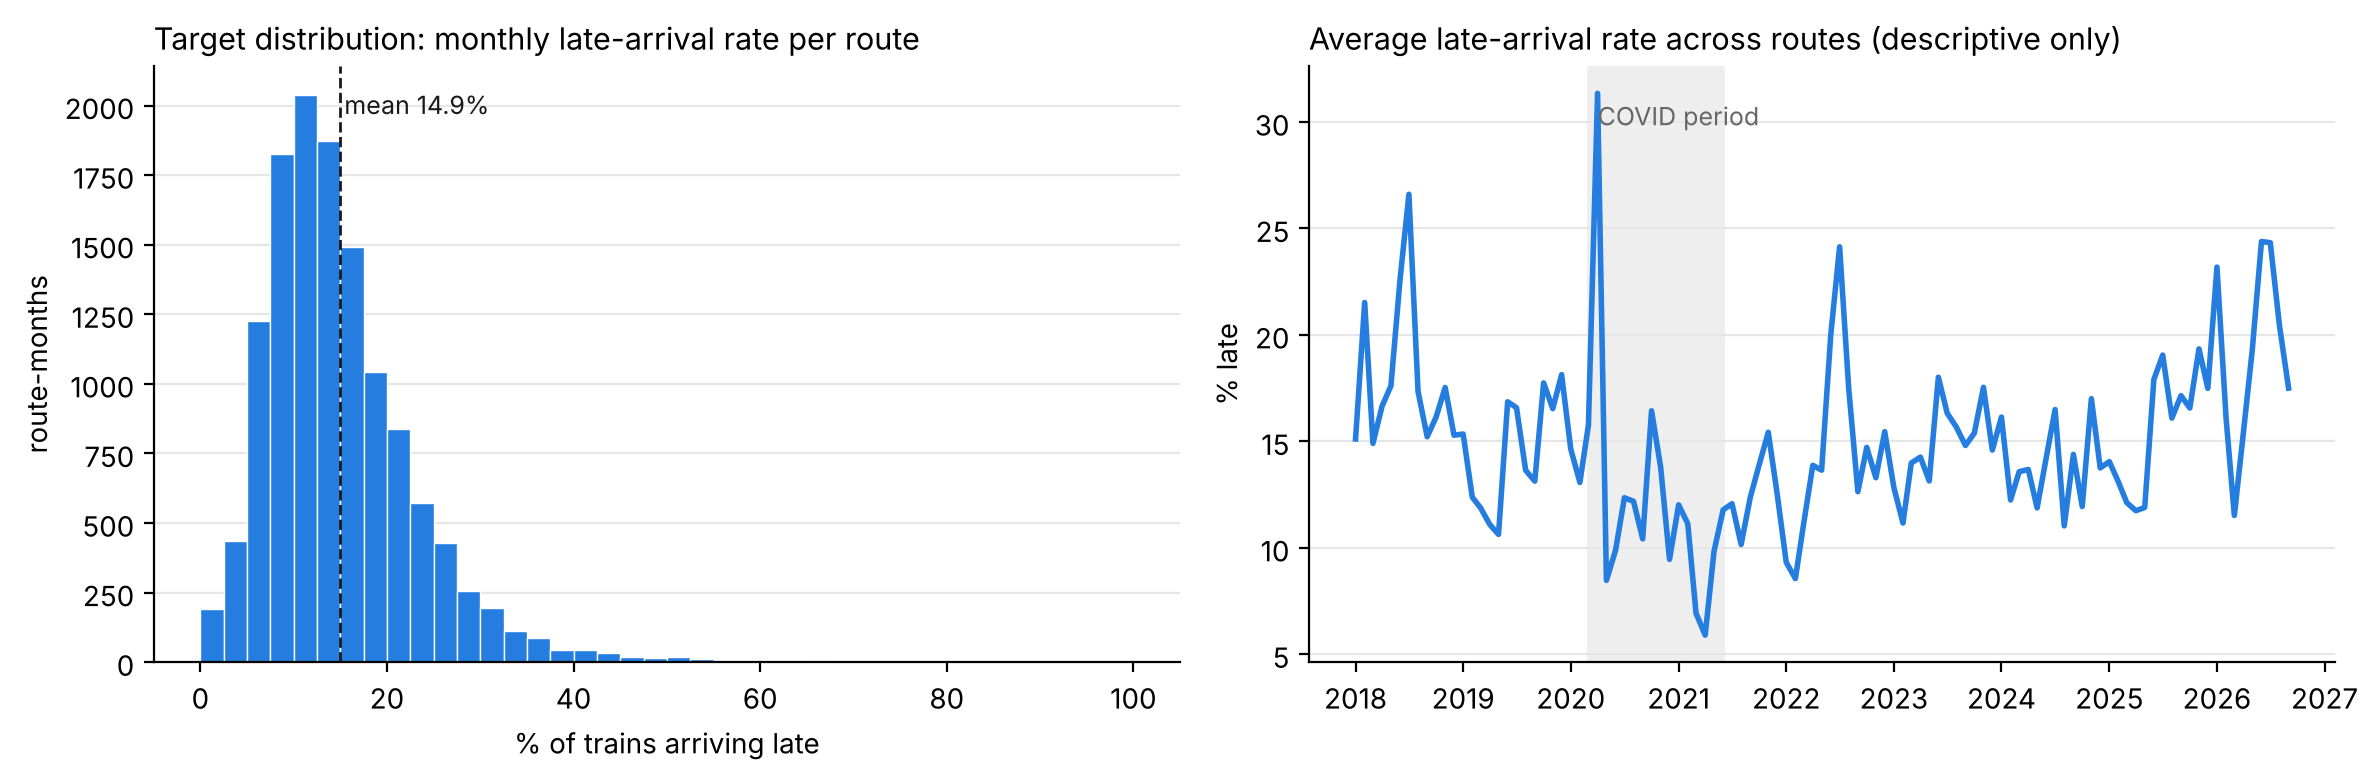

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.hist(df["late_rate"] * 100, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(df["late_rate"].mean() * 100, color=INK, linewidth=1, linestyle="--")
ax.text(df["late_rate"].mean() * 100 + 0.5, ax.get_ylim()[1] * 0.92,
        f"mean {df['late_rate'].mean()*100:.1f}%", color=INK, fontsize=9)
ax.set_title("Target distribution: monthly late-arrival rate per route", loc="left", fontsize=11)
ax.set_xlabel("% of trains arriving late"); ax.set_ylabel("route-months")
style(ax)

ax = axes[1]
monthly = df.groupby("date")["late_rate"].mean() * 100
ax.plot(monthly.index, monthly.values, color=BLUE, linewidth=2)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"), color="#eeeeee", zorder=0)
ax.text(pd.Timestamp("2020-04-01"), ax.get_ylim()[1] * 0.95, "COVID period", fontsize=9, color="#666666", va="top")
ax.set_title("Average late-arrival rate across routes (descriptive only)", loc="left", fontsize=11)
ax.set_ylabel("% late"); style(ax)

plt.tight_layout()
plt.savefig(FIG_DIR / "eda_target.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading guide for the group (fill in after running):**
- Is the target skewed? Are there outlier months with a very high late rate?
- Is there visible seasonality (summer, winter)? Is there a trend?
- How strongly does the COVID period (2020-2021) differ? We keep it in the data for now and will test excluding it in Week 3.
- Caveat from the publisher: one TGV can count in several routes, so route-level rows are not independent and must not be summed to a national figure. We only use this table at route level.

## 4. Feature engineering and leakage audit

We frame the task as **one-step-ahead forecasting**: when predicting month *t* for a route, everything up to month *t-1* is known. Features are therefore built only from past months, the timetable and the calendar. Everything measured during month *t* itself (delays at departure, mean delays, delay-cause percentages, cancellations) is an outcome of that month and is excluded.

In [7]:
def add_lag(frame, col, k, name):
    right = frame[["liaison", "date", col]].copy()
    right["date"] = right["date"] + pd.DateOffset(months=k)   # value from k months ago lands on month t
    right = right.rename(columns={col: name})
    return frame.merge(right, on=["liaison", "date"], how="left")

feat = df.copy()
for k in (1, 2, 3, 12):
    feat = add_lag(feat, "late_rate", k, f"lag{k}")
feat["lag_mean3"] = feat[["lag1", "lag2", "lag3"]].mean(axis=1)
feat["month"] = feat["date"].dt.month
feat["month_sin"] = np.sin(2 * np.pi * feat["month"] / 12)
feat["month_cos"] = np.cos(2 * np.pi * feat["month"] / 12)
feat = feat.sort_values(["liaison", "date"]).reset_index(drop=True)
assert len(feat) == len(df), "lag merge changed the number of rows"

NUM_COLS = ["lag1", "lag2", "lag3", "lag12", "lag_mean3", "planned", "duration", "month_sin", "month_cos"]
CAT_COLS = ["service", "dep", "arr"]
TARGET = "late_rate"

audit = pd.DataFrame([
    ("lag1, lag2, lag3, lag12, lag_mean3", "past late rate of the same route", "KEPT", "built from strictly earlier months"),
    ("planned", "scheduled trains in the month", "KEPT", "timetable is known in advance"),
    ("duration", "average trip duration", "KEPT", "structural property of the route"),
    ("month_sin, month_cos", "seasonality", "KEPT", "calendar"),
    ("service, dep, arr", "route identity", "KEPT (categorical)", "structural"),
    ("cancelled, running, late_arr", "same-month outcomes", "DROPPED", "known only after the month ends; late_arr defines the target"),
    ("all other raw columns", "delays at departure, mean delays, delay-cause shares, >15/30/60 min counts, comments",
     "DROPPED", "measured over the very month we predict"),
], columns=["feature(s)", "meaning", "decision", "reason"])
audit

,feature(s),meaning,decision,reason
0,"lag1, lag2, lag3, lag12, lag_mean3",past late rate of the same route,KEPT,built from strictly earlier months
1,planned,scheduled trains in the month,KEPT,timetable is known in advance
2,duration,average trip duration,KEPT,structural property of the route
3,"month_sin, month_cos",seasonality,KEPT,calendar
4,"service, dep, arr",route identity,KEPT (categorical),structural
5,"cancelled, running, late_arr",same-month outcomes,DROPPED,known only after the month ends; late_arr defi...
6,all other raw columns,"delays at departure, mean delays, delay-cause ...",DROPPED,measured over the very month we predict


In [8]:
print("Share of rows with a missing lag (cold start or gap in the series):")
display((feat[["lag1", "lag2", "lag3", "lag12", "lag_mean3"]].isna().mean() * 100).round(1).to_frame("% missing"))

Share of rows with a missing lag (cold start or gap in the series):


,% missing
lag1,1.7
lag2,2.9
lag3,4.0
lag12,13.4
lag_mean3,1.2


## 5. Train / validation / test split (temporal)

A random split would let the model see later months while predicting earlier ones, which overstates performance. We split **by time**: the last 12 months are the test set, the 12 months before are validation (used to tune the regularisation of the linear baseline), everything earlier is training. Imputers, scalers and encoders are fitted on the training set only, inside a scikit-learn `Pipeline`.

In [9]:
months = np.sort(feat["date"].unique())
assert len(months) > VAL_MONTHS + TEST_MONTHS + 12, "not enough months for this split"
test_start = months[-TEST_MONTHS]
val_start = months[-(TEST_MONTHS + VAL_MONTHS)]
feat["split"] = np.where(feat["date"] >= test_start, "test",
                 np.where(feat["date"] >= val_start, "val", "train"))

train = feat[feat["split"] == "train"].copy()
val = feat[feat["split"] == "val"].copy()
test = feat[feat["split"] == "test"].copy()
assert train["date"].max() < val["date"].min() <= val["date"].max() < test["date"].min()

summary = (feat.groupby("split")
           .agg(rows=("date", "size"), first_month=("date", "min"), last_month=("date", "max"),
                routes=("liaison", "nunique"), mean_late_rate=(TARGET, "mean"))
           .loc[["train", "val", "test"]])
summary["first_month"] = summary["first_month"].dt.strftime("%Y-%m")
summary["last_month"] = summary["last_month"].dt.strftime("%Y-%m")
display(summary.round(4))

unseen = set(test["liaison"]) - set(train["liaison"])
print(f"Test routes never seen in training: {len(unseen)} "
      f"({test['liaison'].isin(unseen).mean()*100:.1f}% of test rows)")

,rows,first_month,last_month,routes,mean_late_rate
split,,,,,
train,9888,2018-01,2024-09,130,0.1439
val,1494,2024-10,2025-09,135,0.1473
test,1452,2025-10,2026-09,121,0.1880


Test routes never seen in training: 2 (1.7% of test rows)


## 6. Baselines (regression)

**Task:** regression of `late_rate` (a share between 0 and 1; an error of 0.01 is one percentage point).

| ID | Baseline | Why it is useful |
|----|----------|------------------|
| B0 | Global training mean | Floor: any model must beat a constant |
| B1 | Mean late rate per route (training) | Simple statistical model; captures that some routes are chronically late |
| B2 | Persistence: last month's late rate | Strong naive forecast for time series |
| B3 | Seasonal naive: same month last year | Tests whether seasonality is stable |
| **B4** | **Ridge linear regression** (lags, calendar, scheduled traffic, route one-hot) | **Our reference baseline** that Week 3 models must beat |

Where a lag is missing, B2 and B3 fall back to the route mean (B1), then to the global mean. **Metrics:** MAE (main, easy to read in percentage points), RMSE (penalises large misses), R². Model selection (Ridge alpha) uses validation MAE only; the test set is looked at once, at the end.

In [10]:
global_mean = train[TARGET].mean()
route_mean = train.groupby("liaison")[TARGET].mean()

def pred_b0(d): return np.full(len(d), global_mean)
def pred_b1(d): return d["liaison"].map(route_mean).fillna(global_mean).to_numpy()
def pred_b2(d): return d["lag1"].fillna(pd.Series(pred_b1(d), index=d.index)).to_numpy()
def pred_b3(d): return d["lag12"].fillna(pd.Series(pred_b1(d), index=d.index)).to_numpy()

def make_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ])

FEATURES = NUM_COLS + CAT_COLS
alpha_rows, best = [], None
for alpha in [0.1, 1, 10, 100, 1000]:
    m = Pipeline([("pre", make_pre()), ("model", Ridge(alpha=alpha))]).fit(train[FEATURES], train[TARGET])
    mae_val = mean_absolute_error(val[TARGET], np.clip(m.predict(val[FEATURES]), 0, 1))
    alpha_rows.append({"alpha": alpha, "val MAE": mae_val})
    if best is None or mae_val < best[0]:
        best = (mae_val, alpha, m)
ridge, BEST_ALPHA = best[2], best[1]
print("Ridge alpha selected on validation:", BEST_ALPHA)
pd.DataFrame(alpha_rows).round(5)

Ridge alpha selected on validation: 10


,alpha,val MAE
0,0.1,0.03898
1,1.0,0.03892
2,10.0,0.03880
3,100.0,0.03924
4,1000.0,0.03973


In [11]:
def pred_b4(d): return np.clip(ridge.predict(d[FEATURES]), 0, 1)

def metrics(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))), "R2": r2_score(y, p)}

models = {
    "B0 Global mean": pred_b0,
    "B1 Route mean": pred_b1,
    "B2 Persistence (lag1)": pred_b2,
    "B3 Seasonal naive (lag12)": pred_b3,
    "B4 Ridge regression": pred_b4,
}
rows = []
for name, fn in models.items():
    for split_name, d in (("val", val), ("test", test)):
        rows.append({"model": name, "split": split_name, **metrics(d[TARGET], fn(d))})
res = pd.DataFrame(rows)
res_wide = res.pivot(index="model", columns="split", values=["MAE", "RMSE", "R2"]).round(4)
res_wide = res_wide[[("MAE", "val"), ("MAE", "test"), ("RMSE", "val"), ("RMSE", "test"), ("R2", "val"), ("R2", "test")]]
res_wide

MAE            RMSE              R2        
split                         val    test     val    test     val    test
model                                                                    
B0 Global mean             0.0541  0.0694  0.0785  0.0980 -0.0019 -0.2546
B1 Route mean              0.0430  0.0609  0.0675  0.0866  0.2594  0.0218
B2 Persistence (lag1)      0.0467  0.0566  0.0639  0.0751  0.3351  0.2640
B3 Seasonal naive (lag12)  0.0508  0.0633  0.0784  0.0874 -0.0010  0.0018
B4 Ridge regression        0.0388  0.0524  0.0569  0.0704  0.4738  0.3534

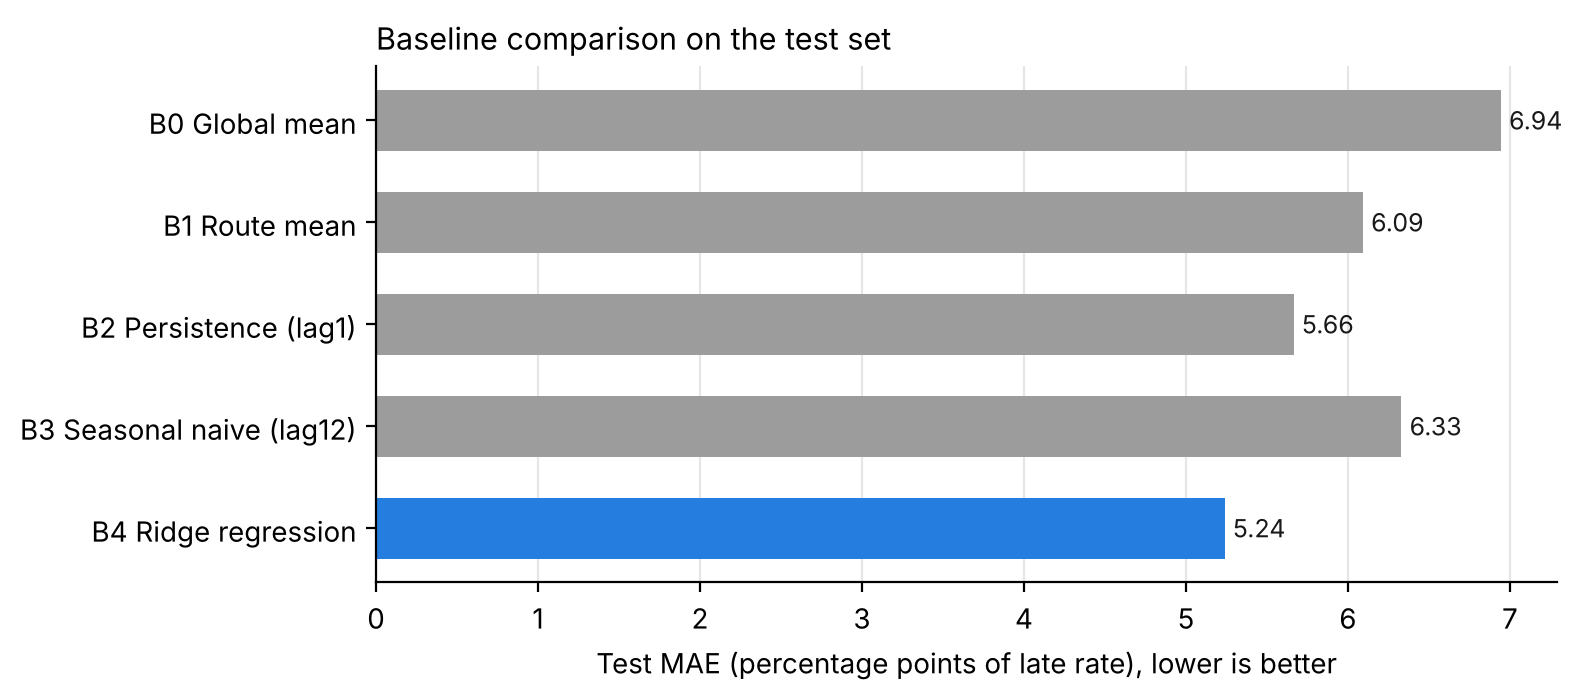

In [12]:
t = res[res["split"] == "test"].set_index("model")["MAE"] * 100
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [BLUE if m.startswith("B4") else GREY for m in t.index]
bars = ax.barh(t.index[::-1], t.values[::-1], color=colors[::-1], height=0.6)
for b, v in zip(bars, t.values[::-1]):
    ax.text(v + 0.05, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", fontsize=9, color=INK)
ax.set_xlabel("Test MAE (percentage points of late rate), lower is better")
ax.set_title("Baseline comparison on the test set", loc="left", fontsize=11)
style(ax); ax.grid(axis="x", color="#e6e6e6", linewidth=0.8); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "baseline_mae_test.png", dpi=150, bbox_inches="tight"); plt.show()

### 6.1 First error analysis (Ridge, test set)

In [13]:
test = test.assign(pred_b4=pred_b4(test), abs_err=lambda d: (d[TARGET] - d["pred_b4"]).abs())
by_route = (test.groupby("liaison")
            .agg(months=("abs_err", "size"), MAE=("abs_err", "mean"), mean_late=(TARGET, "mean"))
            .query("months >= 6").sort_values("MAE", ascending=False))
print("Routes with the largest test error (at least 6 test months):")
display(by_route.head(10).round(4))
print("MAE by service:")
display(test.groupby("service")["abs_err"].agg(["size", "mean"]).round(4))

Routes with the largest test error (at least 6 test months):


,months,MAE,mean_late
liaison,,,
INTERNATIONAL | PARIS EST > STUTTGART,12,0.2209,0.5744
NATIONAL | BORDEAUX ST JEAN > TOURCOING,12,0.1261,0.2151
NATIONAL | MARSEILLE ST CHARLES > TOURCOING,12,0.1097,0.2170
INTERNATIONAL | PARIS EST > FRANCFORT,12,0.0907,0.3342
NATIONAL | MACON LOCHE > PARIS LYON,12,0.0802,0.3377
NATIONAL | LILLE > MARSEILLE ST CHARLES,12,0.0800,0.2503
NATIONAL | MARNE LA VALLEE > MARSEILLE ST CHARLES,12,0.0766,0.2560
INTERNATIONAL | PARIS LYON > ITALIE,12,0.0763,0.2489
NATIONAL | PARIS LYON > CHAMBERY CHALLES LES EAUX,12,0.0750,0.2525


MAE by service:


,size,mean
service,,
INTERNATIONAL,144,0.0660
NATIONAL,1308,0.0509


## 7. Secondary view: classification baseline

To keep the option open for a classification framing, we define a "high-delay month" as a route-month whose late rate exceeds the **75th percentile of the training set** (threshold computed on training data only). Baselines: majority class, persistence (last month high), and logistic regression with balanced class weights. Metrics: F1 on the positive class, ROC-AUC and PR-AUC, because the positive class is a minority.

In [14]:
thr = train[TARGET].quantile(0.75)
for d in (train, val, test):
    d["high"] = (d[TARGET] > thr).astype(int)
print(f"Threshold (train 75th percentile): {thr:.3f} | positive rate train/val/test: "
      f"{train['high'].mean():.2f} / {val['high'].mean():.2f} / {test['high'].mean():.2f}")

clf = Pipeline([("pre", make_pre()),
                ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))]
               ).fit(train[FEATURES], train["high"])

def clf_scores(d, kind):
    y = d["high"]
    if kind == "majority":
        return {"F1": f1_score(y, np.zeros(len(d), dtype=int), zero_division=0), "ROC-AUC": 0.5, "PR-AUC": y.mean()}
    if kind == "persistence":
        p = (d["lag1"].fillna(0) > thr).astype(int)
        return {"F1": f1_score(y, p, zero_division=0), "ROC-AUC": roc_auc_score(y, d["lag1"].fillna(d["lag1"].median())),
                "PR-AUC": average_precision_score(y, d["lag1"].fillna(d["lag1"].median()))}
    proba = clf.predict_proba(d[FEATURES])[:, 1]
    return {"F1": f1_score(y, (proba > 0.5).astype(int), zero_division=0),
            "ROC-AUC": roc_auc_score(y, proba), "PR-AUC": average_precision_score(y, proba)}

rows = []
for kind, name in [("majority", "C0 Majority class"), ("persistence", "C1 Persistence (lag1 > thr)"),
                   ("logreg", "C2 Logistic regression")]:
    for sp, d in (("val", val), ("test", test)):
        rows.append({"model": name, "split": sp, **clf_scores(d, kind)})
pd.DataFrame(rows).pivot(index="model", columns="split", values=["F1", "ROC-AUC", "PR-AUC"]).round(3)

Threshold (train 75th percentile): 0.180 | positive rate train/val/test: 0.25 / 0.26 / 0.46


F1        ROC-AUC        PR-AUC       
split                         test    val    test    val   test    val
model                                                                 
C0 Majority class            0.000  0.000   0.500  0.500  0.461  0.260
C1 Persistence (lag1 > thr)  0.689  0.581   0.768  0.797  0.737  0.629
C2 Logistic regression       0.705  0.667   0.810  0.870  0.795  0.720

## 8. Save the clean dataset and results

In [15]:
out_cols = ["liaison", "date", "service", "dep", "arr", "duration", "planned", "cancelled", "running",
            "late_arr", TARGET, "lag1", "lag2", "lag3", "lag12", "lag_mean3", "month", "split"]
feat[out_cols].to_csv(PROC_DIR / "tgv_liaisons_clean.csv", index=False)
res_wide.to_csv(PROC_DIR / "baseline_results_regression.csv")
pd.DataFrame(log, columns=["step", "rows"]).to_csv(PROC_DIR / "cleaning_log.csv", index=False)
print("Saved:", sorted(p.name for p in PROC_DIR.iterdir()))

Saved: ['.gitkeep', 'baseline_results_regression.csv', 'cleaning_log.csv', 'tgv_liaisons_clean.csv', 'week3_grid_search_summary.csv', 'week3_results_regression.csv']


## 9. Summary for the Week 2 report (to complete after running)

1. **Cleaning:** how many rows were removed and why (see cleaning log), how many rows had an unusable station (`0`).
2. **Target:** distribution, seasonality, effect of COVID.
3. **Split:** train / validation / test date ranges and sizes (table above).
4. **Baselines:** which model wins on the test set, by how much, and whether Ridge improves on persistence. If persistence is hard to beat, say so: it tells us how much of the delay rate is simply inertia.
5. **Limitations:** target definition is ours; one train counts in several routes; monthly aggregation hides daily events; rows with unusable stations were dropped.
6. **Next (Week 3):** random forest and gradient boosting, feature selection comparison, hyperparameter tuning on validation, time-series cross-validation, SHAP or permutation importance.

## 10. Week 3 (Lab 6): hyperparameter search and ensembles

Goal: find out whether tuned models and ensembles beat the Ridge baseline (B4) and the persistence forecast (B2), and whether the gain is large enough to matter.

**Protocol**
- **Development set = train + validation** (all months before the last 12). The last 12 months stay untouched until the final comparison below, and are used once.
- **Time-aware cross-validation.** A random k-fold would let the model train on months that come after the ones it is scored on. We use 5 expanding-window folds instead: each fold trains on every month up to a cut-off and is scored on the following 6 months (table below).
- **One metric for every choice:** MAE of predictions clipped to [0, 1], the same as in Week 2.
- **Models:** tuned Ridge, decision tree, HistGradientBoosting and bagged trees, then a voting ensemble and a stacking ensemble built from them. Every hyperparameter is chosen with the cross-validation above, never with the test set.

In [16]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, HistGradientBoostingRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance
import time, pickle

def mae_clipped(y, p):
    return mean_absolute_error(y, np.clip(p, 0, 1))
SCORER = make_scorer(mae_clipped, greater_is_better=False)

def make_pre_dense():
    """Same preprocessing as the baselines, but dense output (HistGradientBoosting needs it)."""
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ])

# Development set = train + validation. The test set (last 12 months) is not touched until the final test evaluation.
dev = pd.concat([train, val]).sort_values(["date", "liaison"]).reset_index(drop=True)
X_dev, y_dev = dev[FEATURES], dev[TARGET]

N_FOLDS, BLOCK = 5, 6   # 5 expanding-window folds, each validated on the 6 months that follow its training window
def forward_folds(d, n_folds=N_FOLDS, block=BLOCK):
    ms = np.sort(d["date"].unique())
    folds = []
    for k in range(n_folds):
        end = len(ms) - (n_folds - 1 - k) * block
        v_months = ms[end - block:end]
        tr = np.where(d["date"] < v_months[0])[0]
        va = np.where(d["date"].isin(v_months))[0]
        assert d["date"].iloc[tr].max() < d["date"].iloc[va].min()   # training strictly before validation
        folds.append((tr, va))
    return folds

FOLDS = forward_folds(dev)
fold_of = np.full(len(dev), -1)
for k, (tr, va) in enumerate(FOLDS):
    fold_of[va] = k
pd.DataFrame([{"fold": k + 1,
               "train months": f"{dev['date'].iloc[tr].min():%Y-%m} to {dev['date'].iloc[tr].max():%Y-%m}",
               "train rows": len(tr),
               "validation months": f"{dev['date'].iloc[va].min():%Y-%m} to {dev['date'].iloc[va].max():%Y-%m}",
               "validation rows": len(va)} for k, (tr, va) in enumerate(FOLDS)]).set_index("fold")

,train months,train rows,validation months,validation rows
fold,,,,
1,2018-01 to 2023-03,7718,2023-04 to 2023-09,726
2,2018-01 to 2023-09,8444,2023-10 to 2024-03,720
3,2018-01 to 2024-03,9164,2024-04 to 2024-09,724
4,2018-01 to 2024-09,9888,2024-10 to 2025-03,726
5,2018-01 to 2025-03,10614,2025-04 to 2025-09,768


### Grid search

Each grid is small on purpose: the search runs on 5 folds and the boosting grid alone takes about five minutes on 2 cores.
- **Ridge:** the same `alpha` values as Week 2, now chosen by cross-validation instead of one validation year.
- **Decision tree:** depth and minimum leaf size, the two settings that control how much the tree can memorise.
- **HistGradientBoosting:** learning rate, depth, number of iterations, L2 penalty and leaf size (48 combinations).
- **Bagging of trees:** 100 trees, each on a random share of the rows and half of the features. Only depth, leaf size and the row share are searched.

The table reports the best mean cross-validated MAE, its spread over the folds, and the MAE on the training part of the same folds. A large gap between the two would signal overfitting.

In [17]:
SEARCHES = {
    "Ridge": (Pipeline([("pre", make_pre_dense()), ("model", Ridge())]),
              {"model__alpha": [0.1, 1, 10, 100, 1000]}),
    "Decision tree": (Pipeline([("pre", make_pre_dense()), ("model", DecisionTreeRegressor(random_state=SEED))]),
                      {"model__max_depth": [3, 5, 8, 12, None], "model__min_samples_leaf": [5, 20, 50]}),
    "HistGradientBoosting": (Pipeline([("pre", make_pre_dense()), ("model", HistGradientBoostingRegressor(random_state=SEED))]),
                      {"model__learning_rate": [0.03, 0.1], "model__max_depth": [3, 6, None],
                       "model__max_iter": [200, 500], "model__l2_regularization": [0, 1],
                       "model__min_samples_leaf": [20, 50]}),
    "Bagging trees": (Pipeline([("pre", make_pre_dense()),
                                ("model", BaggingRegressor(estimator=DecisionTreeRegressor(random_state=SEED),
                                                           n_estimators=100, max_features=0.5, random_state=SEED))]),
                      {"model__estimator__max_depth": [6, 10], "model__estimator__min_samples_leaf": [5, 20],
                       "model__max_samples": [0.5, 0.8]}),
}
searches, search_rows = {}, []
for name, (pipe, grid) in SEARCHES.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=FOLDS, scoring=SCORER, n_jobs=2, refit=True, return_train_score=True)
    gs.fit(X_dev, y_dev)
    searches[name] = gs
    r = pd.DataFrame(gs.cv_results_)
    search_rows.append({"model": name, "candidates": len(r), "best CV MAE": -gs.best_score_,
                        "std over folds": r.loc[gs.best_index_, "std_test_score"],
                        "train MAE (best)": -r.loc[gs.best_index_, "mean_train_score"],
                        "search time (s)": time.time() - t0,
                        "best parameters": {k.split("__", 1)[1]: v for k, v in gs.best_params_.items()}})
pd.DataFrame(search_rows).set_index("model").round(4)

,candidates,best CV MAE,std over folds,train MAE (best),search time (s),best parameters
model,,,,,,
Ridge,5,0.0373,0.0033,0.0451,2.0331,{'alpha': 100}
Decision tree,15,0.0400,0.0039,0.0451,4.5122,"{'max_depth': 5, 'min_samples_leaf': 20}"
HistGradientBoosting,48,0.0376,0.0025,0.0406,296.0304,"{'l2_regularization': 1, 'learning_rate': 0.1,..."
Bagging trees,8,0.0370,0.0036,0.0386,43.2567,"{'estimator__max_depth': 10, 'estimator__min_s..."


In [18]:
# Best values, and whether any best value sits on the border of a grid with three or more values (None = no depth limit counts as the largest).
for name, gs in searches.items():
    edge = []
    for p, values in gs.param_grid.items():
        if len(values) < 3:
            continue
        key = lambda x: np.inf if x is None else x
        if gs.best_params_[p] in (min(values, key=key), max(values, key=key)):
            edge.append(p.split("__", 1)[1])
    print(f"{name:22s} best: { {k.split('__', 1)[1]: v for k, v in gs.best_params_.items()} }")
    print(f"{'':22s} on the border of a grid with 3+ values: {edge if edge else 'none'}")

Ridge                  best: {'alpha': 100}
                       on the border of a grid with 3+ values: none
Decision tree          best: {'max_depth': 5, 'min_samples_leaf': 20}
                       on the border of a grid with 3+ values: none
HistGradientBoosting   best: {'l2_regularization': 1, 'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 200, 'min_samples_leaf': 50}
                       on the border of a grid with 3+ values: ['max_depth']
Bagging trees          best: {'estimator__max_depth': 10, 'estimator__min_samples_leaf': 5, 'max_samples': 0.8}
                       on the border of a grid with 3+ values: none


### Ensembles

- **Voting:** the average of the tuned Ridge, HistGradientBoosting and bagged trees. The single tree is left out because the bagged trees already contain it.
- **Stacking:** a non-negative linear model learns how to weight the same three models. scikit-learn's `StackingRegressor` needs cross-validation folds that partition the data, which expanding windows do not, so we stack by hand: the meta-model of fold *k* is trained only on out-of-fold predictions from folds before *k*. It is therefore first evaluated on fold 2, and all comparisons in the summary table use folds 2 to 5 so that every model is scored on the same months.
- Out-of-fold predictions are produced by refitting each model on the past of each fold, so no model sees the months it is scored on.

In [19]:
best = {n: gs.best_estimator_ for n, gs in searches.items()}

def oof_predict(model):
    """Out-of-fold predictions on the validation blocks (each fold refits the model on its own past only)."""
    p = np.full(len(dev), np.nan)
    for tr, va in FOLDS:
        m = clone(model).fit(X_dev.iloc[tr], y_dev.iloc[tr])
        p[va] = np.clip(m.predict(X_dev.iloc[va]), 0, 1)
    return p

def fold_mae(p, folds=range(N_FOLDS)):
    return np.array([np.abs(y_dev.to_numpy()[FOLDS[k][1]] - p[FOLDS[k][1]]).mean() for k in folds])

def persistence_oof():
    p = np.full(len(dev), np.nan)
    for tr, va in FOLDS:
        rm = dev.iloc[tr].groupby("liaison")[TARGET].mean()
        gm = dev.iloc[tr][TARGET].mean()
        v = dev.iloc[va]
        p[va] = v["lag1"].fillna(v["liaison"].map(rm)).fillna(gm).to_numpy()
    return p

voting = Pipeline([("pre", make_pre_dense()),
                   ("model", VotingRegressor([("ridge", clone(best["Ridge"].named_steps["model"])),
                                              ("hgb", clone(best["HistGradientBoosting"].named_steps["model"])),
                                              ("bag", clone(best["Bagging trees"].named_steps["model"]))]))])

oof = {"B2 Persistence (lag1)": persistence_oof()}
for n in ["Ridge", "Decision tree", "HistGradientBoosting", "Bagging trees"]:
    oof[n] = oof_predict(best[n])
oof["Voting (mean of Ridge, HGB, Bagging)"] = oof_predict(voting)

# Stacking with forward chaining. The meta-model for fold k is trained only on out-of-fold predictions of folds before k,
# so it is first evaluated on fold 2. A non-negative linear model keeps the weights readable.
BASES = ["Ridge", "HistGradientBoosting", "Bagging trees"]
stack_oof = np.full(len(dev), np.nan)
for k in range(1, N_FOLDS):
    past = np.isin(fold_of, range(k))
    cur = fold_of == k
    meta = LinearRegression(positive=True).fit(np.column_stack([oof[b][past] for b in BASES]), y_dev[past])
    stack_oof[cur] = np.clip(meta.predict(np.column_stack([oof[b][cur] for b in BASES])), 0, 1)
oof["Stacking (non-negative linear meta)"] = stack_oof

fold_tab = pd.DataFrame({n: fold_mae(p) for n, p in oof.items()}) * 100
fold_tab.index = [f"fold {i + 1}" for i in range(N_FOLDS)]
print("Validation MAE per fold, in percentage points (stacking starts at fold 2):")
display(fold_tab.round(2).T)

Validation MAE per fold, in percentage points (stacking starts at fold 2):


,fold 1,fold 2,fold 3,fold 4,fold 5
B2 Persistence (lag1),4.37,4.47,4.38,4.26,5.06
Ridge,3.52,3.79,3.52,3.48,4.34
Decision tree,4.06,4.07,3.68,3.53,4.64
HistGradientBoosting,3.75,3.88,3.50,3.49,4.16
Bagging trees,3.46,3.85,3.47,3.37,4.35
"Voting (mean of Ridge, HGB, Bagging)",3.48,3.77,3.43,3.41,4.22
Stacking (non-negative linear meta),NaN,3.86,3.53,3.38,4.25


In [20]:
rows = []
for n in oof:
    f = fold_tab[n]
    rows.append({"model": n, "MAE folds 2-5 (pp)": f.loc["fold 2":].mean(), "std (pp)": f.loc["fold 2":].std(),
                 "MAE folds 1-5 (pp)": f.mean() if not f.isna().any() else np.nan})
cv_summary = pd.DataFrame(rows).set_index("model").round(3)
display(cv_summary)

meta_all = LinearRegression(positive=True).fit(np.column_stack([oof[b][fold_of >= 0] for b in BASES]), y_dev[fold_of >= 0])
print("Stacking weights on all out-of-fold predictions:",
      dict(zip(BASES, meta_all.coef_.round(3))), "| intercept:", round(float(meta_all.intercept_), 4))

,MAE folds 2-5 (pp),std (pp),MAE folds 1-5 (pp)
model,,,
B2 Persistence (lag1),4.543,0.352,4.509
Ridge,3.782,0.398,3.730
Decision tree,3.980,0.496,3.997
HistGradientBoosting,3.758,0.324,3.756
Bagging trees,3.759,0.444,3.699
"Voting (mean of Ridge, HGB, Bagging)",3.707,0.380,3.661
Stacking (non-negative linear meta),3.757,0.388,NaN


Stacking weights on all out-of-fold predictions: {'Ridge': np.float64(0.603), 'HistGradientBoosting': np.float64(0.032), 'Bagging trees': np.float64(0.553)} | intercept: -0.0234


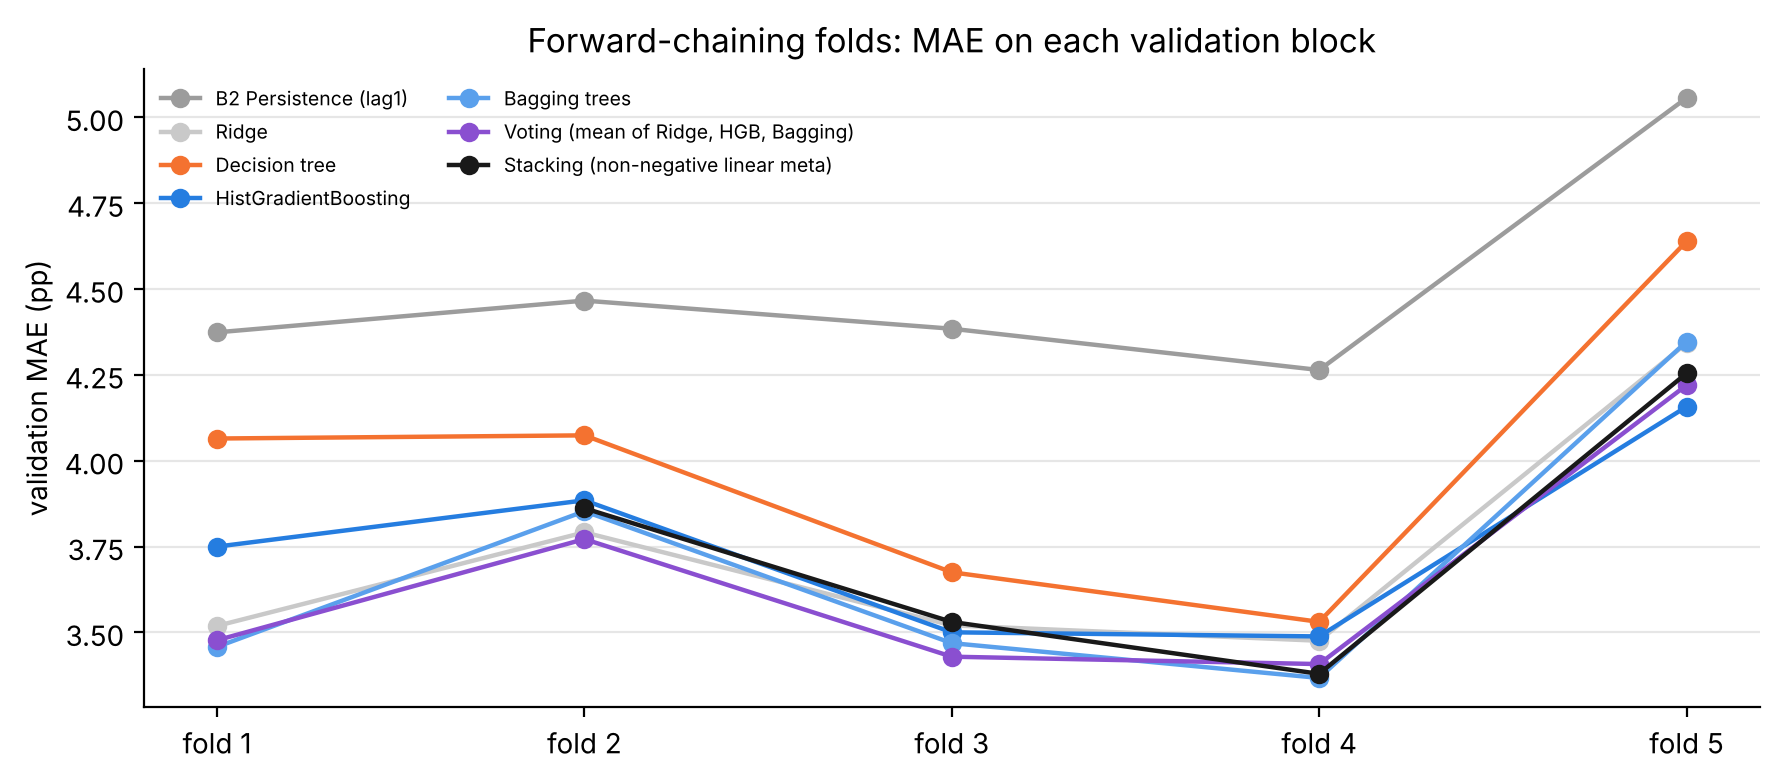

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
style(ax)
for n, c in zip(fold_tab.columns, [GREY, "#c9c9c9", ORANGE, BLUE, "#5aa0ec", "#8a4fd0", INK]):
    ax.plot(fold_tab.index, fold_tab[n], marker="o", label=n, color=c, linewidth=1.6)
ax.set_ylabel("validation MAE (pp)")
ax.set_title("Forward-chaining folds: MAE on each validation block")
ax.legend(fontsize=7, frameon=False, ncol=2)
fig.tight_layout(); fig.savefig(FIG_DIR / "week3_cv_folds.png", dpi=150); plt.show()

### Final comparison on the test set

Every model is refitted on train + validation and applied once to the last 12 months. B2 needs no fitting. The Week 2 Ridge (B4) was fitted on the training months only, which is why its test MAE differs slightly from the tuned Ridge below.

The test set has only 12 months, and errors within a month are strongly correlated. To see whether the differences are larger than the noise, the second table resamples whole months with replacement (4000 times) and gives a 95% interval for the MAE difference with the tuned Ridge. Inference time and size are measured on this machine and only rank the models.

In [22]:
# Refit every model on train + validation, then predict the untouched test set once.
fitted = {n: clone(best[n]).fit(X_dev, y_dev) for n in ["Ridge", "Decision tree", "HistGradientBoosting", "Bagging trees"]}
voting_fit = clone(voting).fit(X_dev, y_dev)

def predict_stack(X):
    return np.clip(meta_all.predict(np.column_stack([np.clip(fitted[b].predict(X), 0, 1) for b in BASES])), 0, 1)

PRED = {
    "B2 Persistence (lag1)": lambda X: pred_b2(test),
    "Ridge": lambda X: np.clip(fitted["Ridge"].predict(X), 0, 1),
    "Decision tree": lambda X: np.clip(fitted["Decision tree"].predict(X), 0, 1),
    "HistGradientBoosting": lambda X: np.clip(fitted["HistGradientBoosting"].predict(X), 0, 1),
    "Bagging trees": lambda X: np.clip(fitted["Bagging trees"].predict(X), 0, 1),
    "Voting (mean of Ridge, HGB, Bagging)": lambda X: np.clip(voting_fit.predict(X), 0, 1),
    "Stacking (non-negative linear meta)": predict_stack,
}
OBJECTS = {"Ridge": ["Ridge"], "Decision tree": ["Decision tree"], "HistGradientBoosting": ["HistGradientBoosting"],
           "Bagging trees": ["Bagging trees"], "Voting (mean of Ridge, HGB, Bagging)": ["voting"],
           "Stacking (non-negative linear meta)": BASES}
def obj(k): return voting_fit if k == "voting" else fitted[k]

def time_predict(fn, X, reps=5):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(X); ts.append(time.perf_counter() - t0)
    return np.median(ts) / len(X) * 1e6

X_test, y_test = test[FEATURES], test[TARGET].to_numpy()
rows, abs_err = [], {}
for n, fn in PRED.items():
    p = fn(X_test)
    abs_err[n] = np.abs(y_test - p)
    m = metrics(y_test, p)
    rows.append({"model": n, "test MAE (pp)": m["MAE"] * 100, "test RMSE (pp)": m["RMSE"] * 100, "test R2": m["R2"],
                 "inference (us/row)": time_predict(fn, X_test) if n in OBJECTS else np.nan,
                 "size (KB)": sum(len(pickle.dumps(obj(k))) for k in OBJECTS[n]) / 1024 if n in OBJECTS else np.nan})
test_tab = pd.DataFrame(rows).set_index("model")
test_tab = test_tab.join(cv_summary[["MAE folds 2-5 (pp)"]].rename(columns={"MAE folds 2-5 (pp)": "CV MAE folds 2-5 (pp)"}))
b4 = res.query("model == 'B4 Ridge regression' and split == 'test'").iloc[0]
print(f"Week 2 reference, Ridge fitted on train only: test MAE {b4['MAE']*100:.2f} pp, RMSE {b4['RMSE']*100:.2f} pp, R2 {b4['R2']:.3f}")
test_tab.round(3)

Week 2 reference, Ridge fitted on train only: test MAE 5.24 pp, RMSE 7.04 pp, R2 0.353


,test MAE (pp),test RMSE (pp),test R2,inference (us/row),size (KB),CV MAE folds 2-5 (pp)
model,,,,,,
B2 Persistence (lag1),5.665,7.508,0.264,NaN,NaN,4.543
Ridge,5.085,6.744,0.406,3.434,5.736,3.782
Decision tree,5.129,7.049,0.351,3.449,9.597,3.980
HistGradientBoosting,4.642,6.468,0.454,9.157,168.452,3.758
Bagging trees,4.907,6.644,0.424,38.858,3599.337,3.759
"Voting (mean of Ridge, HGB, Bagging)",4.815,6.516,0.446,49.828,3765.275,3.707
Stacking (non-negative linear meta),4.758,6.327,0.477,56.235,3773.525,3.757


In [23]:
# Month-block bootstrap: resample the 12 test months with replacement, since errors within a month are correlated.
rng = np.random.default_rng(SEED)
t_months = test["date"].to_numpy()
blocks = [np.where(t_months == m)[0] for m in np.unique(t_months)]
def block_boot(a, b, n_boot=4000):
    d = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(blocks), len(blocks))
        ii = np.concatenate([blocks[p] for p in pick])
        d.append(abs_err[a][ii].mean() - abs_err[b][ii].mean())
    return np.percentile(d, [2.5, 97.5]) * 100

ref = "Ridge"
rows = []
for n in abs_err:
    if n == ref: continue
    lo, hi = block_boot(n, ref)
    rows.append({"model": n, "MAE minus tuned Ridge (pp)": (abs_err[n].mean() - abs_err[ref].mean()) * 100,
                 "95% interval": f"[{lo:+.2f}, {hi:+.2f}]", "interval excludes 0": bool(lo > 0 or hi < 0)})
pd.DataFrame(rows).set_index("model").round(3)

,MAE minus tuned Ridge (pp),95% interval,interval excludes 0
model,,,
B2 Persistence (lag1),0.579,"[-0.28, +1.44]",False
Decision tree,0.044,"[-0.42, +0.43]",False
HistGradientBoosting,-0.443,"[-1.00, +0.02]",False
Bagging trees,-0.179,"[-0.44, +0.08]",False
"Voting (mean of Ridge, HGB, Bagging)",-0.271,"[-0.54, -0.03]",True
Stacking (non-negative linear meta),-0.328,"[-0.65, -0.03]",True


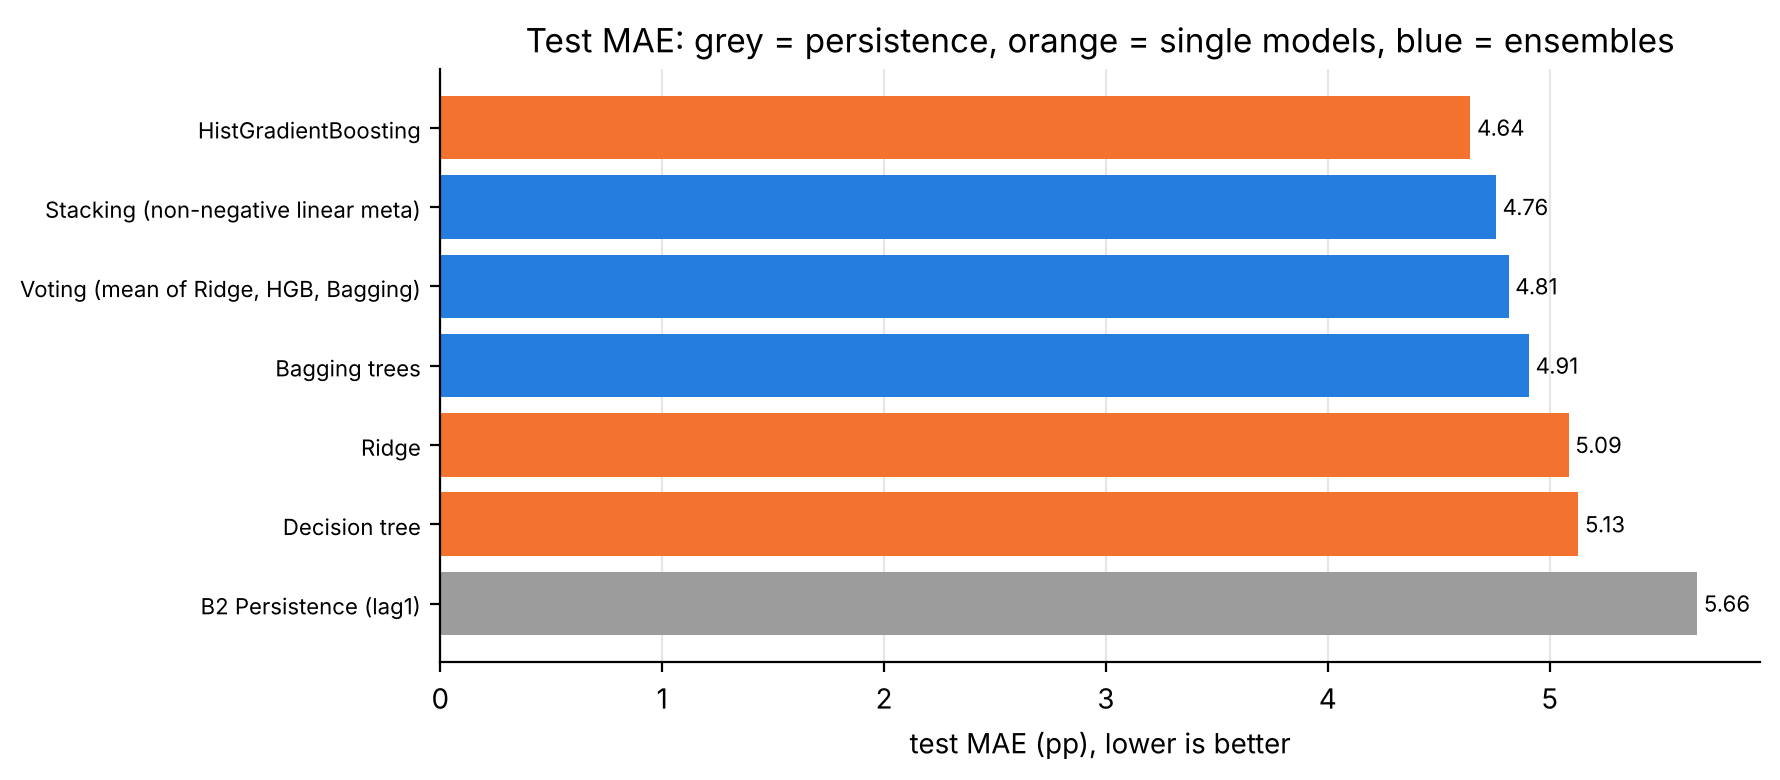

In [24]:
fig, ax = plt.subplots(figsize=(9, 4))
style(ax)
order = test_tab["test MAE (pp)"].sort_values().index
colors = [BLUE if n in ("Voting (mean of Ridge, HGB, Bagging)", "Stacking (non-negative linear meta)", "Bagging trees") else
          (GREY if n.startswith("B2") else ORANGE) for n in order]
ax.barh(range(len(order)), test_tab.loc[order, "test MAE (pp)"], color=colors)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8); ax.invert_yaxis()
for i, v in enumerate(test_tab.loc[order, "test MAE (pp)"]):
    ax.text(v + 0.03, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("test MAE (pp), lower is better"); ax.grid(axis="x", color="#e6e6e6"); ax.grid(axis="y", visible=False)
ax.set_title("Test MAE: grey = persistence, orange = single models, blue = ensembles")
fig.tight_layout(); fig.savefig(FIG_DIR / "week3_test_mae.png", dpi=150); plt.show()

### Classification view

The predicted late rate can also be used as a score for the "high-delay month" label from Week 2 (late rate above the training 75th percentile). F1 uses that same threshold on the predicted rate, ROC-AUC and PR-AUC use the predicted rate directly.

In [25]:
rows = []
for n, fn in PRED.items():
    s = fn(X_test)
    y = test["high"]
    rows.append({"model": n, "F1 (score > train threshold)": f1_score(y, (s > thr).astype(int)),
                 "ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s)})
pd.DataFrame(rows).set_index("model").round(3)

,F1 (score > train threshold),ROC-AUC,PR-AUC
model,,,
B2 Persistence (lag1),0.689,0.769,0.737
Ridge,0.626,0.798,0.783
Decision tree,0.674,0.790,0.748
HistGradientBoosting,0.705,0.826,0.825
Bagging trees,0.664,0.813,0.811
"Voting (mean of Ridge, HGB, Bagging)",0.668,0.818,0.813
Stacking (non-negative linear meta),0.685,0.809,0.799


### Which features matter

Permutation importance of the best single model by cross-validation, fitted on the folds before the last validation block and scored on that block. Each bar is the MAE increase when one feature is shuffled; the whiskers are the standard deviation over 10 shuffles.

Permutation importance of HistGradientBoosting, fitted on folds before the last validation block:


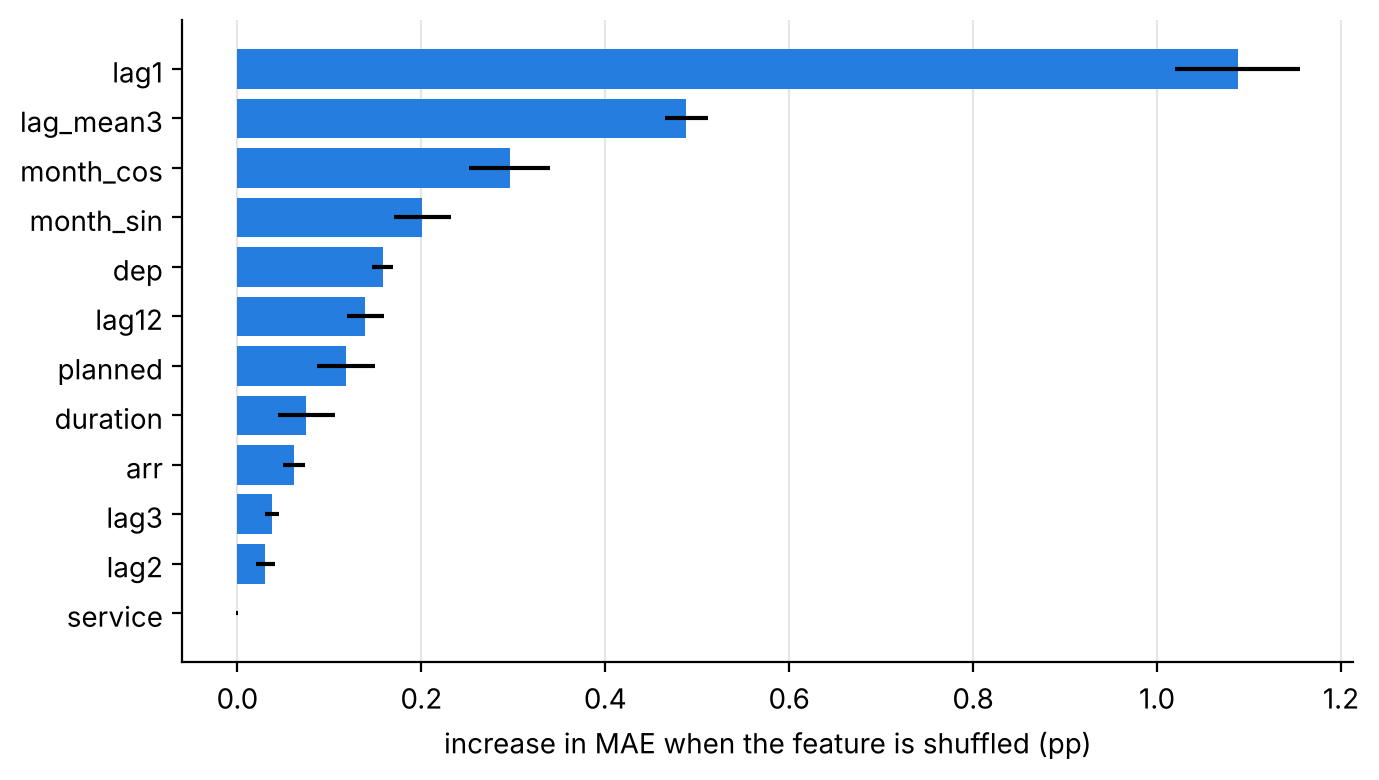

,MAE increase (pp)
lag1,1.088
lag_mean3,0.488
month_cos,0.296
month_sin,0.201
dep,0.158
lag12,0.139
planned,0.118
duration,0.075
arr,0.062
lag3,0.037


In [26]:
cv_best_single = cv_summary.loc[["Ridge", "Decision tree", "HistGradientBoosting", "Bagging trees"], "MAE folds 2-5 (pp)"].idxmin()
tr, va = FOLDS[-1]
m_imp = clone(best[cv_best_single]).fit(X_dev.iloc[tr], y_dev.iloc[tr])
pi = permutation_importance(m_imp, X_dev.iloc[va], y_dev.iloc[va], scoring=SCORER, n_repeats=10, random_state=SEED, n_jobs=2)
imp = pd.Series(pi.importances_mean * 100, index=FEATURES)   # drop in (negative MAE) score = increase in MAE, in pp
imp_std = pd.Series(pi.importances_std * 100, index=FEATURES)
imp = imp.sort_values()
print(f"Permutation importance of {cv_best_single}, fitted on folds before the last validation block:")
fig, ax = plt.subplots(figsize=(7, 4))
style(ax)
ax.barh(imp.index, imp.values, xerr=imp_std[imp.index].values, color=BLUE)
ax.set_xlabel("increase in MAE when the feature is shuffled (pp)")
ax.grid(axis="x", color="#e6e6e6"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "week3_perm_importance.png", dpi=150); plt.show()
imp.sort_values(ascending=False).round(3).to_frame("MAE increase (pp)")

In [27]:
test_tab.to_csv(PROC_DIR / "week3_results_regression.csv")
pd.DataFrame(search_rows).drop(columns="best parameters").to_csv(PROC_DIR / "week3_grid_search_summary.csv", index=False)
print("Saved:", sorted(p.name for p in PROC_DIR.iterdir()))

Saved: ['.gitkeep', 'baseline_results_regression.csv', 'cleaning_log.csv', 'tgv_liaisons_clean.csv', 'week3_grid_search_summary.csv', 'week3_results_regression.csv']


## 11. Summary of Week 3

**Cross-validation (folds 2 to 5, MAE in percentage points).** Persistence 4.54, Ridge 3.78, decision tree 3.98, HistGradientBoosting 3.76, bagged trees 3.76, voting 3.71, stacking 3.76. Every learned model beats persistence in every fold, and Ridge beats it by about 0.8 pp. Between Ridge, boosting, bagging, voting and stacking the gaps are 0.05 to 0.07 pp, smaller than the spread across folds (0.3 to 0.5 pp), so cross-validation does not separate them. The depth-limited tree is clearly behind.

**Test set (MAE, pp).** Persistence 5.66, Ridge 5.09, tree 5.13, bagged trees 4.91, voting 4.82, stacking 4.76, HistGradientBoosting 4.64. Boosting has the best MAE, stacking the best RMSE (6.33) and R² (0.477). Compared with the tuned Ridge, voting, stacking and boosting gain 0.3 to 0.4 pp, about 5 to 9%. The month-level bootstrap gives intervals that exclude zero only for voting [-0.54, -0.03] and stacking [-0.65, -0.03], and only barely. Boosting [-1.00, +0.02] and bagging [-0.44, +0.08] include zero, and so does the Ridge-versus-persistence interval on the test months [-0.28, +1.44], although Ridge wins in all five validation folds. With 12 test months we cannot rank the top models.

**What drives the predictions.** The last month's late rate (lag1) dominates: shuffling it raises the MAE by 1.09 pp, against 0.49 for the three-month mean and 0.20 to 0.30 for the month-of-year terms. Route identity, scheduled traffic and duration add little, and lag2 and lag3 add nothing once the three-month mean is there. Most of the signal is inertia and seasonality, which is also why a linear model is hard to beat by much.

**Classification view.** Boosting has the best ROC-AUC (0.826) and PR-AUC (0.825). On F1 at the fixed threshold persistence (0.689) is close to boosting (0.705) and ahead of Ridge (0.626), because Ridge's smoothed predictions rarely cross the threshold. AUC is the fairer comparison here.

**Cost.** Ridge is about 6 KB and 3 µs per row. Boosting is about 170 KB and 9 µs. Bagging, voting and stacking are 3.6 to 3.8 MB and 39 to 56 µs, since they hold 100 trees. Stacking costs the same as voting and does not beat it in cross-validation, so its extra complexity is not justified here.

**Choice and caveats.**
- By the rule fixed beforehand (lowest cross-validated MAE), voting is the nominal winner. HistGradientBoosting is within noise of it in cross-validation, has the best test MAE and is about twenty times smaller, so it is the practical alternative. The final report should argue between the two on cost and readability, not on the test numbers.
- Every model has a higher MAE on the test months than in cross-validation, persistence included (5.66 against 4.54). The last year is harder than the validation blocks, so the test numbers should not be compared directly with the cross-validation ones.
- The best boosting depth (3) is the smallest value we tried, so a shallower setting was not explored. Grids with two values per parameter cannot show whether the optimum lies outside.
- The stacking weights (Ridge 0.60, bagging 0.55, boosting 0.03, negative intercept) should not be read as importances: boosting and bagging make correlated predictions and the meta-model keeps only one of them.
- Base models for the test predictions are refitted on more months than the ones that produced the out-of-fold predictions the meta-model learned from.
- Only one dataset split in time was tested. The 12-month test result is one draw, not a general claim.